# 03. Tiền xử lý, cổng tái lập và thực nghiệm chính

Sổ tay chạy tuần tự từ trên xuống dưới, không cần tệp `.py` kèm theo. Dữ liệu tải về nằm trong thư mục `Data`, mọi kết quả và hình nằm trong `Output/chot`.

Mục tiêu của tuần 2 không phải là thắng bất kỳ mô hình nào. Mục tiêu là dựng một hạ tầng đo lường trung thực, để tuần 3 chỉ cần đổi đúng một biến là phương án neo.

Đây là **lần chạy chốt**, `CLIP_SIGMA` bằng 0 và giữ đủ 37 kênh. Số liệu của lần chạy này là số liệu đưa vào báo cáo tuần 2. Hai sổ tay `W2_01_Kiem_tra_do_nhay_trial_1` và `trial_2` chỉ để đo mức ảnh hưởng của hai quyết định tiền xử lý, không thay thế kết quả ở đây.

> **Vị trí trong chuỗi tái lập:** notebook 03 trên tổng số 31. Thứ tự chạy và sơ đồ phụ thuộc nằm trong `README.md`.
>
> **Cần chạy trước:** 02-Tai_du_lieu_PhysioNet_2012.
>
> **Thư mục kết quả:** `Output/processed/chot/`.
>
> **Mã định danh nội bộ:** `W2_01`. Mã này còn xuất hiện trong tên khóa JSON, tên hình và nhật ký chạy; nó được giữ nguyên để không phá phép đối chiếu chéo và mã băm của bản khai báo trước.

## 1. Tham số, gắn Google Drive, khóa phiên bản

In [1]:
#@title Tham số chạy { display-mode: "form" }
PROJECT_DIR = "/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4"  #@param {type:"string"}
SEQ_LEN  = 36    #@param {type:"integer"}
PRED_LEN = 12    #@param {type:"integer"}
N_SEEDS  = 5     #@param {type:"integer"}
EPOCHS   = 60    #@param {type:"integer"}
PATIENCE = 10    #@param {type:"integer"}
BATCH    = 128   #@param {type:"integer"}
LR       = 1e-3  #@param {type:"number"}
SPLIT_SEED = 0   #@param {type:"integer"}
RUN_TAG = "chot"  #@param {type:"string"}
CLIP_SIGMA = 0.0  #@param {type:"number"}
DROP_EMPTY_CHANNELS = False  #@param {type:"boolean"}

# CLIP_SIGMA bằng 0 nghĩa là giữ nguyên mọi giá trị. Đặt 5.0 nếu muốn lặp lại cách
# Nhóm tác giả GraFITi loại các điểm nằm ngoài khoảng năm độ lệch chuẩn.

import os, sys, json, time, random, platform, datetime, importlib, subprocess, tarfile, urllib.request
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
else:
    PROJECT_DIR = os.environ.get("P12_PROJECT", "./AIO2026_Conquer_M4_DLinear_NLinear_Slot4")

PROJECT = Path(PROJECT_DIR)
DATA_RAW = PROJECT / "Data"
OUT = PROJECT / "Output"
# Mỗi lần chạy có một thư mục con riêng trong Output/processed, không ghi đè lẫn nhau.
RUN_DIR = OUT / "processed" / RUN_TAG
PROC = RUN_DIR
RUNS = RUN_DIR / "runs"
FIGS = RUN_DIR / "figures"
LOGS = RUN_DIR / "logs"
for d in (DATA_RAW, OUT, RUN_DIR, PROC, RUNS, FIGS, LOGS):
    d.mkdir(parents=True, exist_ok=True)

print("Thư mục dự án:", PROJECT)
print("Dữ liệu thô  :", DATA_RAW)
print("Nhãn lần chạy:", RUN_TAG)
print("Kết quả      :", RUN_DIR)

Mounted at /content/drive
Thư mục dự án: /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4
Dữ liệu thô  : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Data
Nhãn lần chạy: chot
Kết quả      : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot


Colab thay phiên bản mặc định khá thường xuyên. Ô dưới đây ghi lại phiên bản của lần chạy đầu vào `env_lock.json` và cảnh báo nếu lần chạy sau bị lệch. Không có bước này thì một con số khác đi vài phần nghìn sẽ không truy được nguyên nhân.

In [2]:
REQUIRED = {"numpy": "1.24.0", "torch": "2.0.0", "matplotlib": "3.7.0", "scipy": "1.10.0"}


def ver_tuple(v):
    out = []
    for part in str(v).split(".")[:3]:
        digits = "".join(ch for ch in part if ch.isdigit())
        out.append(int(digits) if digits else 0)
    return tuple(out + [0] * (3 - len(out)))


missing = []
for name, floor in REQUIRED.items():
    try:
        mod = importlib.import_module(name)
        if ver_tuple(mod.__version__) < ver_tuple(floor):
            missing.append(name + ">=" + floor)
    except ImportError:
        missing.append(name + ">=" + floor)

if missing:
    print("Cài bổ sung:", " ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + missing, check=True)

import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
import scipy

ENV = {
    "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    "python": platform.python_version(),
    "platform": platform.platform(),
    "numpy": np.__version__,
    "torch": torch.__version__,
    "matplotlib": matplotlib.__version__,
    "scipy": scipy.__version__,
    "cuda_available": bool(torch.cuda.is_available()),
    "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
}

lock = OUT / "env_lock.json"
if lock.exists():
    old = json.loads(lock.read_text())
    drift = {k: (old.get(k), ENV[k]) for k in REQUIRED if old.get(k) != ENV[k]}
    if drift:
        print("CẢNH BÁO: lệch phiên bản so với lần chạy đầu")
        for k, pair in drift.items():
            print("   ", k, "khóa", pair[0], "hiện tại", pair[1])
    else:
        print("Phiên bản khớp env_lock.json")
else:
    lock.write_text(json.dumps(ENV, indent=2))
    print("Đã ghi", lock)

stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
(LOGS / ("env_" + stamp + ".json")).write_text(json.dumps(ENV, indent=2))
for k, v in ENV.items():
    print(k.ljust(16), v)

Đã ghi /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/env_lock.json
timestamp        2026-10-14T18:03:51
python           3.13.15
platform         Linux-6.6.122+-x86_64-with-glibc2.39
numpy            2.1.3
torch            2.11.0+cu130
matplotlib       3.10.0
scipy            1.16.3
cuda_available   True
device           Tesla T4


## 2. Các hàm vẽ

Bảng màu Okabe và Ito an toàn với người rối loạn sắc giác. Bỏ khung viền trên và bên phải, bỏ lưới, chú giải không viền: đây là quy ước trình bày của hầu hết hội nghị máy học. Mọi hình đều tự sinh từ dữ liệu, không có hình nào lấy từ nguồn ngoài.

In [3]:
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000"]

matplotlib.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "legend.frameon": False,
    "lines.linewidth": 1.4,
    "axes.prop_cycle": matplotlib.cycler(color=PALETTE),
    "figure.constrained_layout.use": True,
})


def save_fig(fig, name):
    path = FIGS / name
    fig.savefig(path)
    print("Đã lưu", path)
    return path


def plot_missingness_by_channel(mask, channel_names, ax):
    rate = mask.mean(axis=(0, 1))
    order = np.argsort(rate)
    y = np.arange(len(order))
    ax.barh(y, rate[order] * 100.0, color=PALETTE[0], height=0.75)
    ax.set_yticks(y)
    ax.set_yticklabels([channel_names[i] for i in order])
    ax.set_xlabel("Tỷ lệ ô giờ có phép đo thật, phần trăm")
    ax.set_ylim(-0.8, len(order) - 0.2)


def plot_observation_heatmap(mask, channel_names, ax, n_records=500):
    dens = mask[:n_records].mean(axis=0).T
    im = ax.imshow(dens, aspect="auto", cmap="Greys", vmin=0.0, vmax=1.0, interpolation="nearest")
    ax.set_yticks(np.arange(len(channel_names)))
    ax.set_yticklabels(channel_names, fontsize=6)
    ax.set_xlabel("Giờ kể từ lúc nhập ICU")
    cb = ax.figure.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
    cb.set_label("Mật độ quan sát")


def plot_delta_t_hist(dt, ax):
    flat = np.asarray(dt).reshape(-1)
    bins = np.arange(0, int(flat.max()) + 2) - 0.5
    ax.hist(flat, bins=bins, color=PALETTE[0], edgecolor="white", linewidth=0.3)
    med = float(np.median(flat))
    ax.axvline(med, color=PALETTE[1], linestyle="--", linewidth=1.0)
    ax.annotate("trung vị = " + str(int(med)) + " giờ",
                xy=(med, ax.get_ylim()[1] * 0.92),
                xytext=(6, 0), textcoords="offset points", color=PALETTE[1])
    ax.set_xlabel(r"$\Delta t$, số giờ kể từ phép đo thật gần nhất")
    ax.set_ylabel("Số cặp kênh và cửa sổ")


def plot_seed_scatter(results, ax, ref=None, ref_label=None):
    from scipy import stats
    names = list(results)
    for i, name in enumerate(names):
        v = np.asarray(results[name], dtype=float)
        m = v.mean()
        ax.scatter(v, np.full_like(v, i, dtype=float), s=18, color=PALETTE[0], alpha=0.6, zorder=3)
        if len(v) > 1:
            half = stats.t.ppf(0.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))
            ax.plot([m - half, m + half], [i, i], color="black", linewidth=1.2, zorder=2)
        ax.scatter([m], [i], marker="|", s=160, color="black", zorder=4)
    if ref is not None:
        ax.axvline(ref, color=PALETTE[1], linestyle="--", linewidth=1.0,
                   label=ref_label or "số đã công bố")
        ax.legend(loc="lower right")
    ax.set_yticks(range(len(names)))
    ax.set_yticklabels(names)
    ax.set_xlabel(r"$\mathrm{MSE}_{\mathrm{obs}}$ trên tập kiểm tra")
    ax.set_ylim(-0.6, len(names) - 0.4)


def plot_curves(curves, ax, xlabel, x=None):
    for name, v in curves.items():
        xs = np.arange(1, len(v) + 1) if x is None else x
        ax.plot(xs, v, marker="o", markersize=3, label=name)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(r"$\mathrm{MSE}_{\mathrm{obs}}$")
    ax.legend()


def plot_example_record(x, mask, channel_names, channels, ax, hour_split=None):
    T = x.shape[0]
    for k, c in enumerate(channels):
        t = np.arange(T)[mask[:, c] > 0]
        v = x[mask[:, c] > 0, c]
        ax.plot(t, v, marker="o", markersize=3, alpha=0.85,
                color=PALETTE[k % len(PALETTE)], label=channel_names[c])
    if hour_split is not None:
        ax.axvline(hour_split - 0.5, color="black", linewidth=1.0, linestyle=":")
    ax.set_xlabel("Giờ kể từ lúc nhập ICU")
    ax.set_ylabel("Giá trị đã chuẩn hóa")
    ax.legend(ncol=2)


print("Đã định nghĩa xong các hàm vẽ")

Đã định nghĩa xong các hàm vẽ


## 3. Dùng lại dữ liệu đã tải

Lần chạy này không tải dữ liệu. Thư mục `Data` đã có sẵn `set-a` và `set-b` từ lần chạy chốt, nên ô dưới đây chỉ kiểm tra sự tồn tại rồi lập danh sách hồ sơ. Dùng chung một bản dữ liệu thô là điều kiện bắt buộc để ba lần chạy so sánh được với nhau.

In [4]:
# Thư mục Data trên Drive chỉ giữ hai tệp nén gốc.
# Trên Colab, trình gắn Drive liệt kê thiếu khi một thư mục có hàng nghìn tệp nhỏ.
# Do đó mọi hồ sơ .txt được giải nén ra đĩa cục bộ của phiên làm việc.
BASE = "https://physionet.org/files/challenge-2012/1.0.0"
LOCAL_RAW = Path("/content/p12_raw") if IN_COLAB else (DATA_RAW / "_giai_nen")
LOCAL_RAW.mkdir(parents=True, exist_ok=True)
SO_HO_SO_MOI_BO = 4000


def dem_txt(d):
    return len(list(d.glob("*.txt"))) if d.exists() else 0


def lay_tep_nen(part):
    tgz = DATA_RAW / (part + ".tar.gz")
    if tgz.exists() and tgz.stat().st_size > 1000000:
        return tgz
    print("Chưa có tệp nén hợp lệ cho", part, "nên tải từ PhysioNet")
    urllib.request.urlretrieve(BASE + "/" + part + ".tar.gz", tgz)
    return tgz


def chuan_bi_bo(part):
    dich = LOCAL_RAW / part
    if dem_txt(dich) >= SO_HO_SO_MOI_BO:
        print("Bộ", part, "đã sẵn sàng trên đĩa cục bộ:", dem_txt(dich), "hồ sơ")
        return dich
    with tarfile.open(lay_tep_nen(part)) as tf:
        tf.extractall(LOCAL_RAW)
    if dem_txt(dich) == 0:
        # Một số bản phát hành giải nén ra thư mục lồng nhau
        found = [q.parent for q in LOCAL_RAW.rglob(part + "/*.txt")]
        assert found, "Giải nén thất bại cho " + part
        dich = found[0]
    n = dem_txt(dich)
    print("Bộ", part, "giải nén ra đĩa cục bộ:", n, "hồ sơ")
    assert n > 100, "Giải nén thiếu cho " + part
    return dich


SET_DIRS = [chuan_bi_bo("set-a"), chuan_bi_bo("set-b")]
RECORD_FILES = sorted(p for d in SET_DIRS for p in d.glob("*.txt"))
print("Tổng số hồ sơ:", len(RECORD_FILES))
assert len(RECORD_FILES) >= 7000, "Số hồ sơ thấp bất thường, kiểm tra hai tệp nén trong Data"

/tmp/ipykernel_932/2810531772.py:29: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tf.extractall(LOCAL_RAW)


Bộ set-a giải nén ra đĩa cục bộ: 4000 hồ sơ
Bộ set-b giải nén ra đĩa cục bộ: 4000 hồ sơ
Tổng số hồ sơ: 8000


## 4. Tiền xử lý

Thứ tự các bước không được đảo. Dựng lưới trước; tính mặt nạ quan sát trên lưới thô; chỉ sau đó mới chuẩn hóa và điền khuyết. Nếu điền khuyết trước khi lấy mặt nạ thì giá trị điền sẽ bị coi là phép đo thật, và toàn bộ phần chẩn đoán neo mất nghĩa.

Giá trị âm trong tệp gốc là ký hiệu khuyết của nhà phát hành, nên bị loại bỏ. Nhiều phép đo trong cùng một giờ được lấy trung bình, giống cách nhóm tác giả tham chiếu gộp theo giờ.

In [5]:
TS_VARS = [
    "Albumin", "ALP", "ALT", "AST", "Bilirubin", "BUN", "Cholesterol", "Creatinine",
    "DiasABP", "FiO2", "GCS", "Glucose", "HCO3", "HCT", "HR", "K", "Lactate", "Mg",
    "MAP", "MechVent", "Na", "NIDiasABP", "NIMAP", "NISysABP", "PaCO2", "PaO2", "pH",
    "Platelets", "RespRate", "SaO2", "SysABP", "Temp", "TropI", "TropT", "Urine",
    "WBC", "Weight",
]
VAR_IDX = {v: i for i, v in enumerate(TS_VARS)}
STATIC_RAW = ["Age", "Gender", "Height", "ICUType"]
T_HOURS = 48


def parse_record(path):
    rid = -1
    static = {k: np.nan for k in STATIC_RAW}
    events = []
    with open(path, "r") as fh:
        header = fh.readline()
        if not header.strip().startswith("Time"):
            return -1, static, events
        for line in fh:
            parts = line.strip().split(",")
            if len(parts) != 3:
                continue
            tstamp, param, val = parts
            try:
                value = float(val)
            except ValueError:
                continue
            if value < 0:
                continue
            if param == "RecordID":
                rid = int(value)
                continue
            if param in static:
                if np.isnan(static[param]):
                    static[param] = value
                if param != "Weight":
                    continue
            if param not in VAR_IDX:
                continue
            hh, mm = tstamp.split(":")
            hour = int(hh) + int(mm) / 60.0
            if hour < 0 or hour >= T_HOURS:
                continue
            events.append((int(hour), VAR_IDX[param], value))
    return rid, static, events


def build_grid(events):
    acc = np.zeros((T_HOURS, len(TS_VARS)), dtype=np.float64)
    cnt = np.zeros((T_HOURS, len(TS_VARS)), dtype=np.float64)
    for h, c, v in events:
        acc[h, c] += v
        cnt[h, c] += 1.0
    mask = (cnt > 0).astype(np.uint8)
    grid = np.where(cnt > 0, acc / np.maximum(cnt, 1.0), 0.0)
    return grid.astype(np.float32), mask


def encode_static(static):
    onehot = np.zeros(4, dtype=np.float32)
    icu = static["ICUType"]
    if not np.isnan(icu) and 1 <= int(icu) <= 4:
        onehot[int(icu) - 1] = 1.0
    vec = np.array([static["Age"], static["Gender"], static["Height"]], dtype=np.float32)
    return np.concatenate([vec, onehot]).astype(np.float32)


print("Số kênh chuỗi thời gian:", len(TS_VARS))

Số kênh chuỗi thời gian: 37


In [6]:
t0 = time.time()
X_list, M_list, S_list, RID_list = [], [], [], []

for i, f in enumerate(RECORD_FILES):
    rid, static, events = parse_record(f)
    if rid < 0:
        continue
    g, m = build_grid(events)
    X_list.append(g)
    M_list.append(m)
    S_list.append(encode_static(static))
    RID_list.append(rid)
    if (i + 1) % 2000 == 0:
        print("   đã đọc", i + 1, "/", len(RECORD_FILES), "hồ sơ")

X_all = np.stack(X_list)
M_all = np.stack(M_list)
S_all = np.stack(S_list)
RID_all = np.asarray(RID_list, dtype=np.int64)

print("Số hồ sơ hợp lệ:", X_all.shape[0], "lưới", X_all.shape[1], "giờ x", X_all.shape[2], "kênh")
print("Tỷ lệ ô trống trên lưới:", round(100.0 * (1.0 - M_all.mean()), 2), "phần trăm")
print("Con số đối chiếu đã công bố theo sự kiện: 85,7 phần trăm")
print("Thời gian đọc:", int(time.time() - t0), "giây")

   đã đọc 2000 / 8000 hồ sơ
   đã đọc 4000 / 8000 hồ sơ
   đã đọc 6000 / 8000 hồ sơ
   đã đọc 8000 / 8000 hồ sơ
Số hồ sơ hợp lệ: 8000 lưới 48 giờ x 37 kênh
Tỷ lệ ô trống trên lưới: 79.76 phần trăm
Con số đối chiếu đã công bố theo sự kiện: 85,7 phần trăm
Thời gian đọc: 8 giây


Chia dữ liệu theo hồ sơ bệnh nhân, không theo dòng thời gian. Trung bình và độ lệch chuẩn dùng để chuẩn hóa chỉ tính trên tập huấn luyện, tại các ô có phép đo thật. Đây là điểm khác biệt có chủ ý so với mã nguồn tham chiếu: nhóm tác giả GraFITi khớp bộ chuẩn hóa trên toàn bộ dữ liệu, gồm cả tập kiểm tra.

Sau chuẩn hóa, các ô không có phép đo được đặt bằng không, tức bằng trung bình tập huấn luyện. Cố ý không dùng phép nội suy tiến, vì nếu nội suy tiến thì hai định nghĩa neo luôn trùng nhau và đề tài mất nghĩa.

In [7]:
keep_ch = np.arange(len(TS_VARS))
if DROP_EMPTY_CHANNELS:
    cover = M_all.mean(axis=(0, 1))
    keep_ch = np.where(cover >= 0.005)[0]
    print("Bỏ các kênh gần như trống:", [TS_VARS[i] for i in range(len(TS_VARS)) if i not in keep_ch])
    X_all = X_all[:, :, keep_ch]
    M_all = M_all[:, :, keep_ch]
CHANNELS = [TS_VARS[i] for i in keep_ch]

rng = np.random.default_rng(SPLIT_SEED)
idx = rng.permutation(X_all.shape[0])
n = len(idx)
n_test = int(round(0.20 * n))
n_val = int(round(0.10 * n))
test_i, val_i, train_i = idx[:n_test], idx[n_test:n_test + n_val], idx[n_test + n_val:]

mu = np.zeros(len(CHANNELS), dtype=np.float32)
sd = np.ones(len(CHANNELS), dtype=np.float32)
for c in range(len(CHANNELS)):
    vals = X_all[train_i][:, :, c][M_all[train_i][:, :, c] == 1]
    if vals.size > 10:
        mu[c] = float(vals.mean())
        s = float(vals.std())
        sd[c] = s if s > 1e-6 else 1.0

s_mu = np.nanmean(S_all[train_i], axis=0)
s_sd = np.nanstd(S_all[train_i], axis=0)
s_sd[s_sd < 1e-6] = 1.0

n_clipped = 0
for name, sel in (("train", train_i), ("val", val_i), ("test", test_i)):
    Xs = (X_all[sel] - mu) / sd
    Ms = M_all[sel].copy()
    if CLIP_SIGMA > 0:
        outlier = (np.abs(Xs) > CLIP_SIGMA) & (Ms == 1)
        n_clipped += int(outlier.sum())
        Ms = np.where(outlier, 0, Ms).astype(np.uint8)
    Xs = np.where(Ms == 1, Xs, 0.0).astype(np.float32)
    Ss = np.where(np.isnan(S_all[sel]), s_mu, S_all[sel])
    Ss = ((Ss - s_mu) / s_sd).astype(np.float32)
    np.savez_compressed(PROC / (name + ".npz"), X=Xs, M=Ms, S=Ss, rid=RID_all[sel])
    print(name + ":", len(sel), "hồ sơ")
if CLIP_SIGMA > 0:
    print("Số điểm bị loại vì vượt ngưỡng sigma:", n_clipped)

meta = {
    "channels": CHANNELS,
    "static": ["Age", "Gender", "Height", "ICUType_1", "ICUType_2", "ICUType_3", "ICUType_4"],
    "mu": mu.tolist(), "sd": sd.tolist(), "T": T_HOURS,
    "split_seed": SPLIT_SEED,
    "norm_scope": "train_only",
    "clip_sigma": CLIP_SIGMA,
    "protocol": "luoi_co_dinh_36h_vao_12h_ra",
    "missing_rate_grid": float(1.0 - M_all.mean()),
    "n_records": int(X_all.shape[0]),
}
(PROC / "meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2))

for f in ("train.npz", "val.npz", "test.npz", "meta.json"):
    assert (PROC / f).exists(), "Thiếu " + f + ". Không chạy tiếp được."
print("Đã ghi đầy đủ bốn tệp vào", PROC)

train: 5600 hồ sơ
val: 800 hồ sơ
test: 1600 hồ sơ
Đã ghi đầy đủ bốn tệp vào /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot


## 5. Khảo sát cấu trúc khuyết

Một con số tổng hợp che mất khác biệt giữa các kênh. Nhịp tim có gần như mọi giờ, còn vài kênh xét nghiệm hầu như không xuất hiện. Ba hình dưới đây là bằng chứng bắt buộc phải có trước khi bàn tới mô hình.

Kích thước tập huấn luyện: (5600, 48, 37) (5600, 48, 37) (5600, 7)
Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot/figures/fig01_missingness_by_channel.png


PosixPath('/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot/figures/fig01_missingness_by_channel.png')

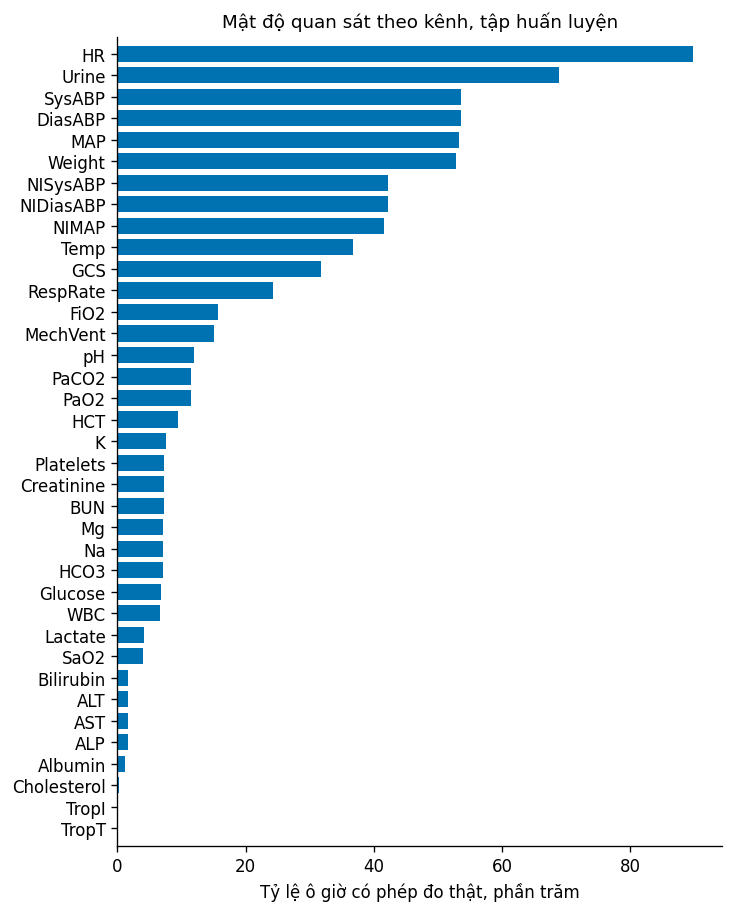

In [8]:
channels = meta["channels"]
train = np.load(PROC / "train.npz")
X, M, S = train["X"], train["M"], train["S"]
print("Kích thước tập huấn luyện:", X.shape, M.shape, S.shape)

fig, ax = plt.subplots(figsize=(6.0, 7.5))
plot_missingness_by_channel(M, channels, ax)
ax.set_title("Mật độ quan sát theo kênh, tập huấn luyện")
save_fig(fig, "fig01_missingness_by_channel.png")

Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot/figures/fig02_observation_heatmap.png


PosixPath('/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot/figures/fig02_observation_heatmap.png')

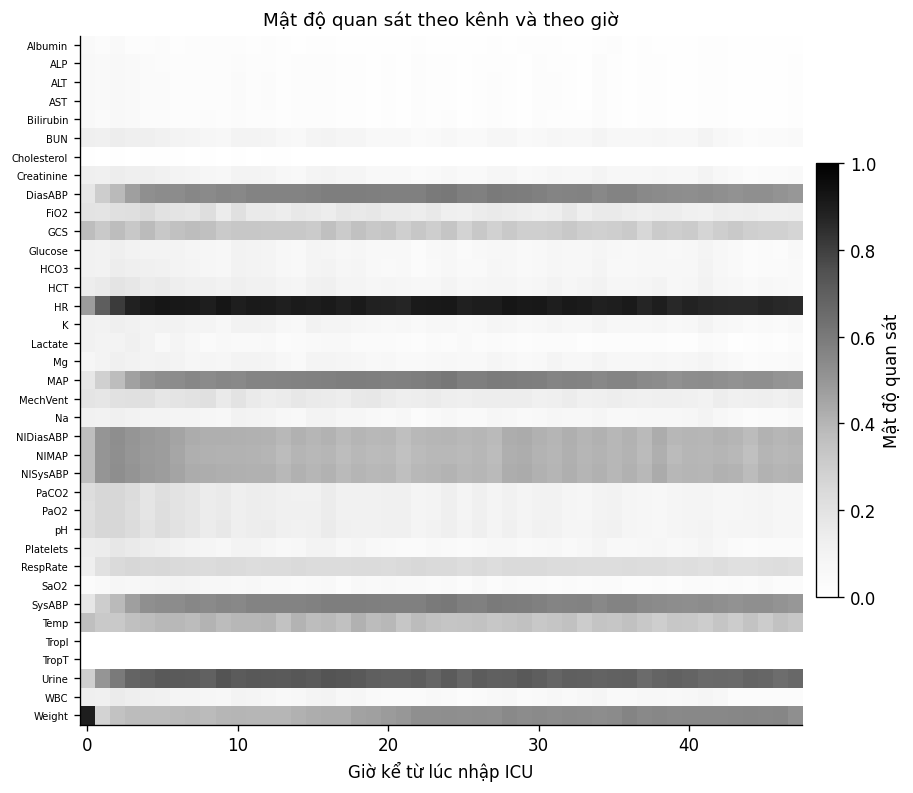

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
plot_observation_heatmap(M, channels, ax)
ax.set_title("Mật độ quan sát theo kênh và theo giờ")
save_fig(fig, "fig02_observation_heatmap.png")

Khoảng trễ tại biên cửa sổ là đại lượng trung tâm của giả thuyết nghiên cứu. Nếu khoảng trễ bằng không ở hầu hết các cặp kênh và cửa sổ thì hai định nghĩa neo trùng nhau, và đề tài không còn đối tượng để so sánh.

Tỷ lệ cặp không có phép đo thật nào trong cửa sổ: 29.99 phần trăm
Tỷ lệ cặp có phép đo thật đúng tại bước cuối: 19.67 phần trăm
Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot/figures/fig03_delta_t.png


PosixPath('/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot/figures/fig03_delta_t.png')

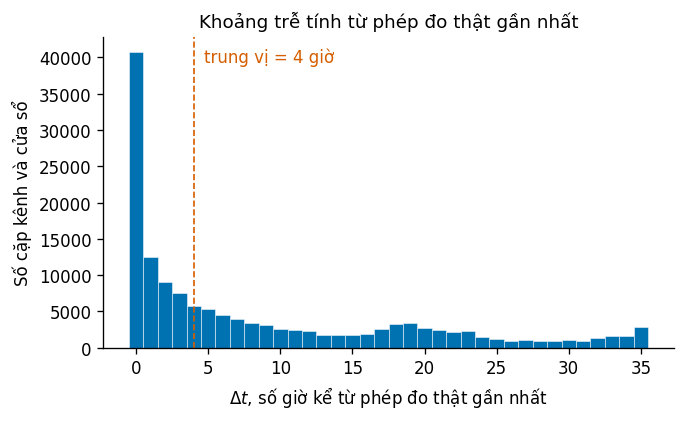

In [10]:
L, H = SEQ_LEN, PRED_LEN
mx = M[:, :L]
pos = np.arange(L).reshape(1, L, 1)
t_star = np.where(mx > 0, pos, -1).max(axis=1)
has_obs = t_star >= 0
delta_t_train = np.where(has_obs, L - 1 - t_star, L)

print("Tỷ lệ cặp không có phép đo thật nào trong cửa sổ:",
      round(100 * (~has_obs).mean(), 2), "phần trăm")
print("Tỷ lệ cặp có phép đo thật đúng tại bước cuối:",
      round(100 * (mx[:, -1, :] > 0).mean(), 2), "phần trăm")

fig, ax = plt.subplots(figsize=(5.6, 3.4))
plot_delta_t_hist(delta_t_train[has_obs], ax)
ax.set_title("Khoảng trễ tính từ phép đo thật gần nhất")
save_fig(fig, "fig03_delta_t.png")

Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot/figures/fig04_example_record.png


PosixPath('/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot/figures/fig04_example_record.png')

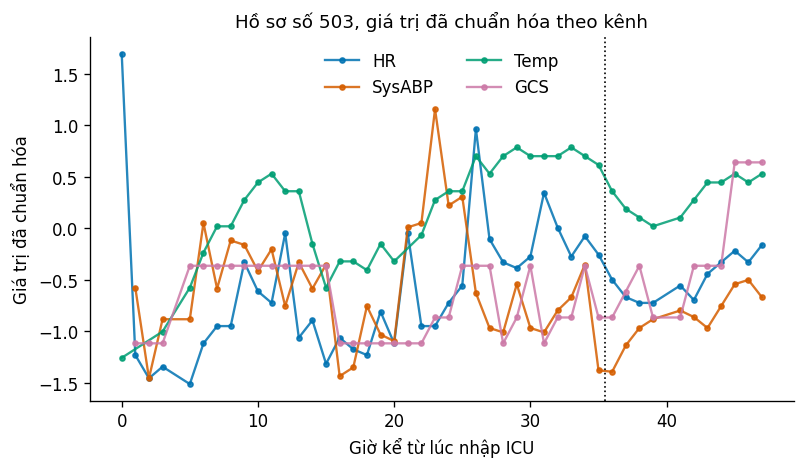

In [11]:
pick = [channels.index(c) for c in ["HR", "SysABP", "Temp", "GCS"] if c in channels]
record = int(np.argmax(M[:, :, pick].sum(axis=(1, 2))))

fig, ax = plt.subplots(figsize=(6.6, 3.8))
plot_example_record(X[record], M[record], channels, pick, ax, hour_split=L)
ax.set_title("Hồ sơ số " + str(record) + ", giá trị đã chuẩn hóa theo kênh")
save_fig(fig, "fig04_example_record.png")

## 6. Mô hình và chỉ số

Một lớp `LinearFamily` bao trùm cả DLinear lấn NLinear. Tham số `kind` chọn họ mô hình, tham số `anchor` chọn cách tính giá trị neo. Viết chung một lớp giúp phép so sánh ở tuần 3 chỉ khác nhau đúng một biến, tránh tình trạng hai nhánh mã lệch nhau ở những chỗ không liên quan.

Bốn phương án neo: A lấy giá trị tại bước cuối của cửa sổ, đúng như NLinear gốc; B lấy phép đo thật gần nhất; C nhân thêm hệ số suy giảm theo khoảng trễ với một tham số dùng chung; D dùng một tham số suy giảm riêng cho từng kênh.

Hàm mất mát và chỉ số đánh giá chỉ tính trên các ô có phép đo thật. Đây là yêu cầu bắt buộc: nếu tính cả ô điền khuyết thì mô hình được thưởng vì dự báo đúng giá trị do chính ta điền vào.

In [12]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

EPS = 1e-8
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def moving_avg(x, kernel_size=25):
    front = x[:, :1, :].repeat(1, (kernel_size - 1) // 2, 1)
    end = x[:, -1:, :].repeat(1, kernel_size - (kernel_size - 1) // 2 - 1, 1)
    xp = torch.cat([front, x, end], dim=1).permute(0, 2, 1)
    return F.avg_pool1d(xp, kernel_size=kernel_size, stride=1).permute(0, 2, 1)


def last_observed(x, mask):
    # Trả về giá trị quan sát thật gần nhất và số giờ đã trôi qua kể từ phép đo đó.
    B, Lx, C = x.shape
    pos = torch.arange(Lx, device=x.device).view(1, Lx, 1).expand(B, Lx, C)
    idx = torch.where(mask > 0, pos, torch.full_like(pos, -1))
    t_star = idx.max(dim=1).values
    has = t_star >= 0
    val = torch.gather(x, 1, t_star.clamp(min=0).unsqueeze(1)).squeeze(1)
    val = torch.where(has, val, torch.zeros_like(val))
    dt = torch.where(has, (Lx - 1 - t_star).float(), torch.full_like(val, float(Lx)))
    return val, dt


class StaticFiLM(nn.Module):
    # Khởi tạo bằng không để lúc đầu khối này là phép đồng nhất, tránh làm xấu điểm khởi đầu.
    def __init__(self, d_static):
        super().__init__()
        self.proj = nn.Linear(d_static, 2)
        nn.init.zeros_(self.proj.weight)
        nn.init.zeros_(self.proj.bias)

    def forward(self, y, s):
        ab = self.proj(s)
        return (1.0 + ab[:, 0].view(-1, 1, 1)) * y + ab[:, 1].view(-1, 1, 1)


class LinearFamily(nn.Module):
    def __init__(self, seq_len, pred_len, n_channels, kind="nlinear", anchor="A",
                 use_mask_channel=True, kernel_size=25, d_static=0):
        super().__init__()
        assert kind in ("dlinear", "nlinear")
        assert anchor in ("A", "B", "C", "D")
        self.L, self.H, self.C = seq_len, pred_len, n_channels
        self.kind, self.anchor = kind, anchor
        self.use_mask_channel = use_mask_channel
        self.kernel_size = kernel_size
        in_dim = seq_len * (2 if use_mask_channel else 1)
        if kind == "dlinear":
            self.lin_seasonal = nn.Linear(in_dim, pred_len)
            self.lin_trend = nn.Linear(in_dim, pred_len)
        else:
            self.lin = nn.Linear(in_dim, pred_len)
        if anchor == "C":
            self.w_decay = nn.Parameter(torch.zeros(1))
        elif anchor == "D":
            self.w_decay = nn.Parameter(torch.zeros(n_channels))
        self.film = StaticFiLM(d_static) if d_static > 0 else None

    def compute_anchor(self, x, mask):
        if self.anchor == "A":
            return x[:, -1, :]
        val, dt = last_observed(x, mask)
        if self.anchor == "B":
            return val
        rate = F.softplus(self.w_decay)
        return torch.exp(-rate.view(1, -1) * dt) * val

    def _flatten(self, x, mask):
        B, Lx, C = x.shape
        xt = x.permute(0, 2, 1).reshape(B * C, Lx)
        if not self.use_mask_channel:
            return xt
        mt = mask.permute(0, 2, 1).reshape(B * C, Lx).float()
        return torch.cat([xt, mt], dim=-1)

    def forward(self, x, mask, s=None):
        B, Lx, C = x.shape
        if self.kind == "nlinear":
            a = self.compute_anchor(x, mask)
            z = self.lin(self._flatten(x - a.unsqueeze(1), mask))
            y = z.view(B, C, self.H).permute(0, 2, 1) + a.unsqueeze(1)
        else:
            trend = moving_avg(x, self.kernel_size)
            zs = self.lin_seasonal(self._flatten(x - trend, mask))
            zt = self.lin_trend(self._flatten(trend, mask))
            y = (zs + zt).view(B, C, self.H).permute(0, 2, 1)
        if self.film is not None and s is not None:
            y = self.film(y, s)
        return y


class Persistence(nn.Module):
    # Đường cơ sở không tham số: giữ nguyên phép đo thật gần nhất cho mọi bước tương lai.
    def __init__(self, pred_len):
        super().__init__()
        self.H = pred_len

    def forward(self, x, mask, s=None):
        val, _ = last_observed(x, mask)
        return val.unsqueeze(1).repeat(1, self.H, 1)


def per_patient_sums(y_hat, y, m):
    m = m.astype(np.float64)
    se = (m * (y_hat - y) ** 2).reshape(len(m), -1).sum(axis=1)
    ae = (m * np.abs(y_hat - y)).reshape(len(m), -1).sum(axis=1)
    cnt = m.reshape(len(m), -1).sum(axis=1)
    return se, ae, cnt


def bootstrap_ci(se, ae, cnt, n_boot=2000, seed=0, alpha=0.05):
    # Lấy mẫu lại ở cấp bệnh nhân, không phải cấp điểm đo, vì các điểm trong cùng
    # Một hồ sơ không độc lập với nhau.
    rng = np.random.default_rng(seed)
    N = len(cnt)
    mses, maes = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        denom = cnt[idx].sum() + EPS
        mses[b] = se[idx].sum() / denom
        maes[b] = ae[idx].sum() / denom
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    per_sample_mae = float(np.mean(ae / np.maximum(cnt, 1.0)))
    return {
        "mse": float(se.sum() / (cnt.sum() + EPS)),
        "mse_ci": [float(np.percentile(mses, lo)), float(np.percentile(mses, hi))],
        "mae": float(ae.sum() / (cnt.sum() + EPS)),
        "mae_ci": [float(np.percentile(maes, lo)), float(np.percentile(maes, hi))],
        "mae_per_sample": per_sample_mae,
    }


print("Cấu hình tính toán:", DEVICE)

Cấu hình tính toán: cuda


Hai cách tính sai số tuyệt đối đều được ghi lại. Cách thứ nhất gộp mọi điểm đo rồi chia một lần; cách thứ hai tính trung bình trong từng hồ sơ trước, sau đó lấy trung bình các hồ sơ. Mã nguồn tham chiếu dùng cách thứ hai cho sai số tuyệt đối nhưng dùng cách thứ nhất cho sai số bình phương, nên hai con số không cùng một mẫu số. Ghi cả hai giúp tránh so sánh lệch thước đo.

In [13]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def load_split(name, L, H):
    d = np.load(PROC / (name + ".npz"))
    Xd, Md, Sd = d["X"], d["M"], d["S"]
    assert Xd.shape[1] >= L + H, "Lưới thời gian ngắn hơn L cộng H"
    x, mxx = Xd[:, :L], Md[:, :L]
    y, myy = Xd[:, L:L + H], Md[:, L:L + H]
    keep = myy.reshape(len(myy), -1).sum(axis=1) > 0
    return (torch.from_numpy(x[keep]).float(), torch.from_numpy(mxx[keep]).float(),
            torch.from_numpy(y[keep]).float(), torch.from_numpy(myy[keep]).float(),
            torch.from_numpy(Sd[keep]).float(), int(keep.sum()), int((~keep).sum()))


SPLITS = {}
for name in ("train", "val", "test"):
    x, mxx, y, myy, s, kept, dropped = load_split(name, SEQ_LEN, PRED_LEN)
    SPLITS[name] = TensorDataset(x, mxx, y, myy, s)
    print(name + ":", "giữ", kept, "hồ sơ, bỏ", dropped, "hồ sơ không có mục tiêu quan sát thật")

N_CH = SPLITS["train"].tensors[0].shape[-1]
print("Số kênh:", N_CH)

train: giữ 5559 hồ sơ, bỏ 41 hồ sơ không có mục tiêu quan sát thật
val: giữ 794 hồ sơ, bỏ 6 hồ sơ không có mục tiêu quan sát thật
test: giữ 1585 hồ sơ, bỏ 15 hồ sơ không có mục tiêu quan sát thật
Số kênh: 37


In [14]:
def run_one(kind, anchor="A", seed=0, static=False, tag=None,
            epochs=None, patience=None, verbose=False):
    """Huấn luyện một cấu hình, đánh giá trên tập kiểm tra, ghi kết quả vào Drive."""
    epochs = EPOCHS if epochs is None else epochs
    patience = PATIENCE if patience is None else patience
    set_seed(seed)
    ds = SPLITS["train"].tensors[4].shape[-1] if static else 0

    if kind == "persistence":
        model = Persistence(PRED_LEN).to(DEVICE)
        n_params = 0
    else:
        model = LinearFamily(SEQ_LEN, PRED_LEN, N_CH, kind=kind, anchor=anchor,
                             d_static=ds).to(DEVICE)
        n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    loaders = {k: DataLoader(v, batch_size=BATCH, shuffle=(k == "train"))
               for k, v in SPLITS.items()}

    t0 = time.time()
    best_val, best_state, bad, history = float("inf"), None, 0, []
    if kind != "persistence":
        opt = torch.optim.Adam(model.parameters(), lr=LR)
        for ep in range(epochs):
            model.train()
            for x, mxx, y, myy, s in loaders["train"]:
                x, mxx, y, myy, s = [t.to(DEVICE) for t in (x, mxx, y, myy, s)]
                opt.zero_grad()
                pred = model(x, mxx, s)
                loss = (myy * (pred - y) ** 2).sum() / (myy.sum() + EPS)
                loss.backward()
                opt.step()
            model.eval()
            with torch.no_grad():
                num = den = 0.0
                for x, mxx, y, myy, s in loaders["val"]:
                    x, mxx, y, myy, s = [t.to(DEVICE) for t in (x, mxx, y, myy, s)]
                    p = model(x, mxx, s)
                    num += float((myy * (p - y) ** 2).sum())
                    den += float(myy.sum())
                vmse = num / (den + EPS)
            history.append(vmse)
            if verbose:
                print("   epoch", ep, "val_mse_obs", round(vmse, 5))
            if vmse < best_val - 1e-6:
                best_val, bad = vmse, 0
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                bad += 1
                if bad >= patience:
                    break
        if best_state is not None:
            model.load_state_dict(best_state)
    train_time = time.time() - t0

    model.eval()
    outs = []
    with torch.no_grad():
        for x, mxx, y, myy, s in loaders["test"]:
            outs.append(model(x.to(DEVICE), mxx.to(DEVICE), s.to(DEVICE)).cpu().numpy())
    yhat = np.concatenate(outs)
    y_true = SPLITS["test"].tensors[2].numpy()
    my_true = SPLITS["test"].tensors[3].numpy()
    se, ae, cnt = per_patient_sums(yhat, y_true, my_true)
    res = bootstrap_ci(se, ae, cnt, seed=seed)

    if tag is not None:
        name = tag
    else:
        name = kind + ("_" + anchor if kind == "nlinear" else "") + ("_static" if static else "") + "_s" + str(seed)
    payload = {"name": name, "kind": kind, "anchor": anchor, "static": static, "seed": seed,
               "seq_len": SEQ_LEN, "pred_len": PRED_LEN, "n_params": n_params,
               "protocol": meta["protocol"],
               "val_mse_obs": best_val if best_val < float("inf") else None,
               "train_time_sec": round(train_time, 2), "device": DEVICE,
               "history": history, "test": res, "env": ENV}
    (RUNS / (name + ".json")).write_text(json.dumps(payload, ensure_ascii=False, indent=2))
    np.savez_compressed(RUNS / (name + "_patient_sums.npz"), se=se, ae=ae, n=cnt)
    print(name.ljust(22), "MSE_obs", round(res["mse"], 4), " MAE_obs", round(res["mae"], 4),
          " ", int(train_time), "giây ", n_params, "tham số")
    return payload


print("Đã định nghĩa hàm huấn luyện")

Đã định nghĩa hàm huấn luyện


## 7. Chạy ba đường cơ sở

Persistence chạy một lần vì không có tham số nên không phụ thuộc hạt giống. Hai mô hình tuyến tính chạy năm hạt giống, đúng số lần lặp mà bài báo gốc của DLinear sử dụng.

In [15]:
all_runs = []
all_runs.append(run_one("persistence", tag="persistence"))

t0 = time.time()
for seed in range(N_SEEDS):
    all_runs.append(run_one("dlinear", seed=seed))
    all_runs.append(run_one("nlinear", anchor="A", seed=seed))
print("Tổng thời gian:", round((time.time() - t0) / 60, 1), "phút")

persistence            MSE_obs 0.5788  MAE_obs 0.4659   0 giây  0 tham số
dlinear_s0             MSE_obs 0.487  MAE_obs 0.4698   15 giây  1752 tham số
nlinear_A_s0           MSE_obs 0.4877  MAE_obs 0.4709   6 giây  876 tham số
dlinear_s1             MSE_obs 0.4876  MAE_obs 0.4718   5 giây  1752 tham số
nlinear_A_s1           MSE_obs 0.4882  MAE_obs 0.4717   6 giây  876 tham số
dlinear_s2             MSE_obs 0.4874  MAE_obs 0.4707   5 giây  1752 tham số
nlinear_A_s2           MSE_obs 0.4882  MAE_obs 0.4725   7 giây  876 tham số
dlinear_s3             MSE_obs 0.4869  MAE_obs 0.4706   6 giây  1752 tham số
nlinear_A_s3           MSE_obs 0.4879  MAE_obs 0.4707   6 giây  876 tham số
dlinear_s4             MSE_obs 0.4871  MAE_obs 0.4701   6 giây  1752 tham số
nlinear_A_s4           MSE_obs 0.4891  MAE_obs 0.4729   5 giây  876 tham số
Tổng thời gian: 1.2 phút


In [16]:
results = {}
for p in all_runs:
    key = p["name"].rsplit("_s", 1)[0] if "_s" in p["name"] else p["name"]
    results.setdefault(key, []).append(p["test"]["mse"])

for k in results:
    v = np.array(results[k])
    sd_v = v.std(ddof=1) if len(v) > 1 else 0.0
    print(k.ljust(16), "n =", len(v), " MSE_obs", round(v.mean(), 4), "+/-", round(sd_v, 4))

mae_p = [p["test"]["mae"] for p in all_runs if p["kind"] == "persistence"][0]
for k in results:
    maes = [p["test"]["mae"] for p in all_runs
            if (p["name"].rsplit("_s", 1)[0] if "_s" in p["name"] else p["name"]) == k]
    print(k.ljust(16), "chỉ số kỹ năng theo MAE so với persistence:",
          round(1 - np.mean(maes) / (mae_p + EPS), 4))

persistence      n = 1  MSE_obs 0.5788 +/- 0.0
dlinear          n = 5  MSE_obs 0.4872 +/- 0.0003
nlinear_A        n = 5  MSE_obs 0.4882 +/- 0.0006
persistence      chỉ số kỹ năng theo MAE so với persistence: 0.0
dlinear          chỉ số kỹ năng theo MAE so với persistence: -0.01
nlinear_A        chỉ số kỹ năng theo MAE so với persistence: -0.0124


Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot/figures/fig05_gate_seeds.png


PosixPath('/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot/figures/fig05_gate_seeds.png')

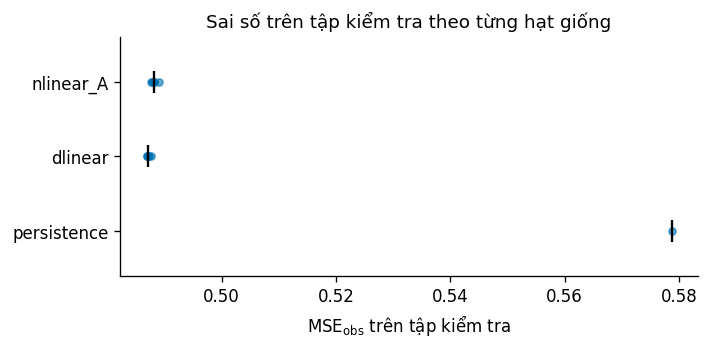

In [17]:
order = [k for k in ["persistence", "dlinear", "nlinear_A"] if k in results]
fig, ax = plt.subplots(figsize=(5.8, 2.8))
plot_seed_scatter({k: results[k] for k in order}, ax)
ax.set_title("Sai số trên tập kiểm tra theo từng hạt giống")
save_fig(fig, "fig05_gate_seeds.png")

Đường cong sai số tăng dần theo bước dự báo là dấu hiệu hạ tầng lành mạnh. Đường phẳng hoặc đi xuống báo hiệu thông tin tương lai đã lọt vào đầu vào qua mặt nạ hoặc qua phép chuẩn hóa.

Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot/figures/fig06_error_by_horizon.png


PosixPath('/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot/figures/fig06_error_by_horizon.png')

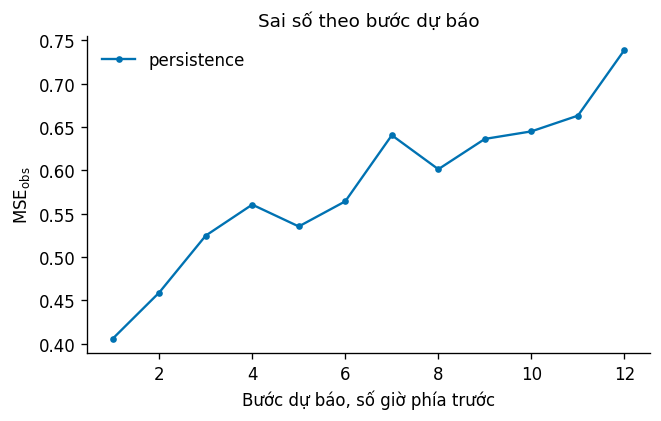

In [18]:
x_te, mx_te, y_te, my_te, s_te, _, _ = load_split("test", SEQ_LEN, PRED_LEN)
with torch.no_grad():
    pred_pers = Persistence(PRED_LEN)(x_te, mx_te).numpy()
my_np, y_np = my_te.numpy(), y_te.numpy()

curves = {"persistence": (my_np * (pred_pers - y_np) ** 2).sum(axis=(0, 2))
                         / (my_np.sum(axis=(0, 2)) + EPS)}

fig, ax = plt.subplots(figsize=(5.4, 3.4))
plot_curves(curves, ax, "Bước dự báo, số giờ phía trước")
ax.set_title("Sai số theo bước dự báo")
save_fig(fig, "fig06_error_by_horizon.png")

## 8. Chẩn đoán giá trị neo

Phần này chuẩn bị nền cho tuần 3 mà không chạy trước phép so sánh bốn phương án. Hai câu hỏi cần trả lời: hai định nghĩa neo khác nhau ở bao nhiêu phần trăm các cặp, và độ lớn khác biệt đủ để mô hình cảm nhận được hay không.

Tỷ lệ cặp kênh và cửa sổ có hai neo trùng nhau: 51.27 phần trăm
Khoảng trễ trung vị: 12.0 giờ
Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot/figures/fig07_anchor_gap.png


PosixPath('/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot/figures/fig07_anchor_gap.png')

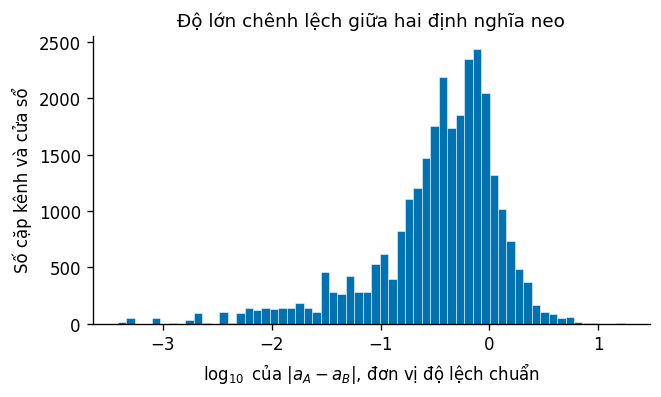

In [19]:
anchor_a = x_te[:, -1, :]
anchor_b, delta_t = last_observed(x_te, mx_te)
same = torch.isclose(anchor_a, anchor_b, atol=1e-6)

print("Tỷ lệ cặp kênh và cửa sổ có hai neo trùng nhau:",
      round(100 * same.float().mean().item(), 2), "phần trăm")
print("Khoảng trễ trung vị:", float(delta_t.median()), "giờ")

gap = (anchor_a - anchor_b).abs().numpy().reshape(-1)
gap = gap[gap > 0]
fig, ax = plt.subplots(figsize=(5.4, 3.2))
ax.hist(np.log10(gap + 1e-6), bins=60, color=PALETTE[0], edgecolor="white", linewidth=0.3)
ax.set_xlabel(r"$\log_{10}$ của $|a_A - a_B|$, đơn vị độ lệch chuẩn")
ax.set_ylabel("Số cặp kênh và cửa sổ")
ax.set_title("Độ lớn chênh lệch giữa hai định nghĩa neo")
save_fig(fig, "fig07_anchor_gap.png")

Giả thuyết nghiên cứu phát biểu rằng lợi ích của việc neo vào phép đo thật tăng theo khoảng trễ. Đồ thị dưới đây kiểm tra chiều hướng đó trên chính đường persistence, tức kiểm tra tiền đề của giả thuyết trước khi tốn công huấn luyện.

Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot/figures/fig08_error_by_delta_t.png


PosixPath('/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot/figures/fig08_error_by_delta_t.png')

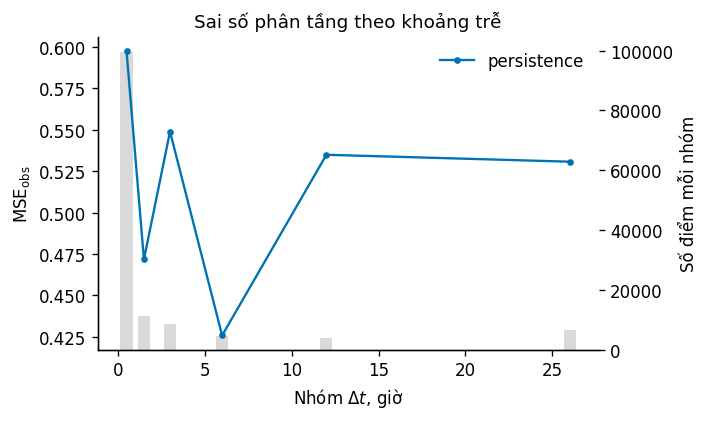

In [20]:
dt_np = delta_t.numpy()
sq = (pred_pers - y_np) ** 2 * my_np
edges = np.array([0, 1, 2, 4, 8, 16, SEQ_LEN])

centers, vals, counts = [], [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    sel = (dt_np >= lo) & (dt_np < hi)
    sel3 = np.repeat(sel[:, None, :], PRED_LEN, axis=1)
    n_pts = (my_np * sel3).sum()
    if n_pts < 100:
        continue
    centers.append((lo + hi) / 2)
    vals.append((sq * sel3).sum() / n_pts)
    counts.append(n_pts)

fig, ax = plt.subplots(figsize=(5.8, 3.4))
plot_curves({"persistence": np.array(vals)}, ax, r"Nhóm $\Delta t$, giờ", x=np.array(centers))
tw = ax.twinx()
tw.bar(centers, counts, width=0.7, color="0.85", zorder=0)
tw.set_ylabel("Số điểm mỗi nhóm")
tw.spines["top"].set_visible(False)
ax.set_zorder(1)
ax.patch.set_visible(False)
ax.set_title("Sai số phân tầng theo khoảng trễ")
save_fig(fig, "fig08_error_by_delta_t.png")

Số liệu chi phí quyết định có chạy nổi bốn phương án neo nhân năm hạt giống trong tuần 3 hay không, với tài nguyên Colab miễn phí.

In [21]:
cost = {}
xb, mb = x_te[:128], mx_te[:128]
for anchor in ("A", "B", "C", "D"):
    net = LinearFamily(SEQ_LEN, PRED_LEN, N_CH, kind="nlinear", anchor=anchor)
    n_params = sum(p.numel() for p in net.parameters())
    t0 = time.time()
    for _ in range(20):
        net(xb, mb).sum().backward()
    ms = 1000 * (time.time() - t0) / 20
    cost[anchor] = {"n_params": n_params, "ms_per_step": round(ms, 2)}
    print("Neo", anchor + ":", n_params, "tham số,", round(ms, 2), "mili giây mỗi bước")

(OUT / "cost.json").write_text(json.dumps(cost, indent=2))

Neo A: 876 tham số, 2.7 mili giây mỗi bước
Neo B: 876 tham số, 2.88 mili giây mỗi bước
Neo C: 877 tham số, 4.59 mili giây mỗi bước
Neo D: 913 tham số, 3.89 mili giây mỗi bước


237

## 9. Tóm tắt phiên chạy

Tệp tổng kết ghi rõ nhãn giao thức. Thiếu nhãn này thì một con số sai số đứng trơ trọi rất dễ bị đem so với con số của giao thức khác, và dẫn tới kết luậ́n sai.

In [22]:
summary = {
    "finished_at": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG,
    "env": ENV,
    "protocol": {
        "ten": "luoi_co_dinh",
        "quan_sat_gio": SEQ_LEN,
        "du_bao_gio": PRED_LEN,
        "muc_tieu": "moi o gio co phep do that trong 12 gio ke tiep",
        "chuan_hoa": "chi tren tap huan luyen",
        "nguon_du_lieu": "set-a va set-b, 8000 ho so",
    },
    "config": {"seq_len": SEQ_LEN, "pred_len": PRED_LEN, "n_seeds": N_SEEDS,
               "epochs": EPOCHS, "patience": PATIENCE, "batch": BATCH, "lr": LR,
               "split_seed": SPLIT_SEED, "clip_sigma": CLIP_SIGMA,
               "drop_empty_channels": DROP_EMPTY_CHANNELS},
    "data": {"n_records": meta["n_records"], "missing_rate_grid": meta["missing_rate_grid"]},
    "results": {k: float(np.mean(v)) for k, v in results.items()},
    "moc_persistence_mse": float([p["test"]["mse"] for p in all_runs if p["kind"] == "persistence"][0]),
    "anchor_cost": cost,
    "figures": sorted(p.name for p in FIGS.glob("*.png")),
}
(RUN_DIR / ("W2_session_summary_" + RUN_TAG + ".json")).write_text(json.dumps(summary, ensure_ascii=False, indent=2))
print(json.dumps(summary, ensure_ascii=False, indent=2))
print()
print("Toàn bộ số liệu, hình và nhật ký đã nằm trong", RUN_DIR)

{
  "finished_at": "2026-10-14T18:05:30",
  "run_tag": "chot",
  "env": {
    "timestamp": "2026-10-14T18:03:51",
    "python": "3.13.15",
    "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
    "numpy": "2.1.3",
    "torch": "2.11.0+cu130",
    "matplotlib": "3.10.0",
    "scipy": "1.16.3",
    "cuda_available": true,
    "device": "Tesla T4"
  },
  "protocol": {
    "ten": "luoi_co_dinh",
    "quan_sat_gio": 36,
    "du_bao_gio": 12,
    "muc_tieu": "moi o gio co phep do that trong 12 gio ke tiep",
    "chuan_hoa": "chi tren tap huan luyen",
    "nguon_du_lieu": "set-a va set-b, 8000 ho so"
  },
  "config": {
    "seq_len": 36,
    "pred_len": 12,
    "n_seeds": 5,
    "epochs": 60,
    "patience": 10,
    "batch": 128,
    "lr": 0.001,
    "split_seed": 0,
    "clip_sigma": 0.0,
    "drop_empty_channels": false
  },
  "data": {
    "n_records": 8000,
    "missing_rate_grid": 0.7975530686936937
  },
  "results": {
    "persistence": 0.5787542076552471,
    "dlinear": 0.4871939811

### Việc tiếp theo

- Giữ nguyên tệp `env_lock.json` để phát hiện lệch phiên bản ở các lần chạy sau.
- Không chạy phép so sánh bốn phương án neo trong tuần 2. Đó là nội dung tuần 3.